# ROBT 407 - Homework 1 Programming Submission

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

SEED = 407

def sgn(z):
    z = np.asarray(z)
    return np.where(z >= 0, 1, -1)

def classification_error(w, X, y):
    return np.mean(sgn(X @ w) != y)

def random_target(rng):
    p1, p2 = rng.uniform(-1, 1, size=(2, 2))
    # Line through p1,p2: A*x1 + B*x2 + C = 0
    A = p1[1] - p2[1]
    B = p2[0] - p1[0]
    C = p1[0]*p2[1] - p2[0]*p1[1]
    return np.array([C, A, B], dtype=float)

def generate_linear_data(N, rng, w_target):
    X2 = rng.uniform(-1, 1, size=(N, 2))
    X = np.column_stack([np.ones(N), X2])
    y = sgn(X @ w_target).astype(int)
    return X, y

def flip_labels(y, frac, rng):
    y_noisy = y.copy()
    k = int(round(frac * len(y)))
    idx = rng.choice(len(y), size=k, replace=False)
    y_noisy[idx] *= -1
    return y_noisy, idx

def pla(X, y, rng, max_updates=1_000_000, w0=None, record=False):
    w = np.zeros(X.shape[1]) if w0 is None else np.array(w0, dtype=float).copy()
    hist = [classification_error(w, X, y)] if record else None

    for t in range(max_updates):
        mis = np.flatnonzero(y * (X @ w) <= 0)
        if len(mis) == 0:
            return w, t, True, np.array(hist) if record else None
        i = rng.choice(mis)
        w += y[i] * X[i]
        if record:
            hist.append(classification_error(w, X, y))

    return w, max_updates, False, np.array(hist) if record else None

def pocket(X, y, T, rng, Xtest=None, ytest=None, w0=None):
    w = np.zeros(X.shape[1]) if w0 is None else np.array(w0, dtype=float).copy()
    w_pocket = w.copy()
    best = classification_error(w_pocket, X, y)

    ein_current = [classification_error(w, X, y)]
    ein_pocket = [best]
    eout_current = []
    eout_pocket = []

    if Xtest is not None:
        eout_current.append(classification_error(w, Xtest, ytest))
        eout_pocket.append(classification_error(w_pocket, Xtest, ytest))

    for _ in range(T):
        mis = np.flatnonzero(y * (X @ w) <= 0)

        if len(mis) > 0:
            i = rng.choice(mis)
            w += y[i] * X[i]

        cur = classification_error(w, X, y)
        if cur < best:
            best = cur
            w_pocket = w.copy()

        ein_current.append(cur)
        ein_pocket.append(best)

        if Xtest is not None:
            eout_current.append(classification_error(w, Xtest, ytest))
            eout_pocket.append(classification_error(w_pocket, Xtest, ytest))

    return {
        "w": w,
        "w_pocket": w_pocket,
        "ein_current": np.array(ein_current),
        "ein_pocket": np.array(ein_pocket),
        "eout_current": np.array(eout_current) if Xtest is not None else None,
        "eout_pocket": np.array(eout_pocket) if Xtest is not None else None,
    }

def plot_line(w, xlim, label):
    xs = np.linspace(xlim[0], xlim[1], 400)
    if abs(w[2]) > 1e-12:
        ys = -(w[0] + w[1]*xs) / w[2]
        plt.plot(xs, ys, label=label)
    else:
        plt.axvline(-w[0]/w[1], label=label)

def plot_binary_data(X, y, title=None):
    plt.scatter(X[y == 1, 1], X[y == 1, 2], s=22, label="+1")
    plt.scatter(X[y == -1, 1], X[y == -1, 2], s=22, label="-1")
    plt.xlabel("$x_1$")
    plt.ylabel("$x_2$")
    if title:
        plt.title(title)
    plt.legend()


In [2]:
import sys
import sklearn

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("Random seed:", SEED)

Python: 3.13.9
NumPy: 2.5.0
scikit-learn: 1.7.2
Random seed: 407


## A.3 - Experiments with PLA

In [3]:
rng = np.random.default_rng(SEED)
w_target = random_target(rng)

results_A3 = []
datasets_A3 = []

for N in [20, 20, 100, 1000]:
    X, y = generate_linear_data(N, rng, w_target)
    w, updates, converged, _ = pla(X, y, rng)
    results_A3.append((N, updates, converged))
    datasets_A3.append((X, y, w))

print("Target weights:", w_target)
for item in results_A3:
    print(f"N={item[0]:4d} | updates={item[1]:4d} | converged={item[2]}")


Target weights: [ 0.47580159 -0.47836835  1.64384351]
N=  20 | updates=  17 | converged=True
N=  20 | updates=  54 | converged=True
N= 100 | updates=  29 | converged=True
N=1000 | updates= 694 | converged=True


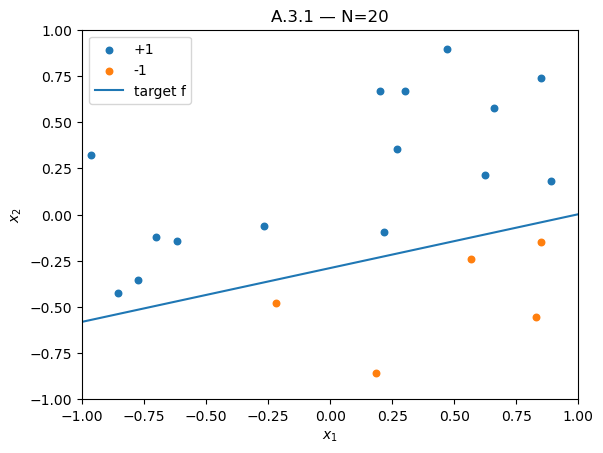

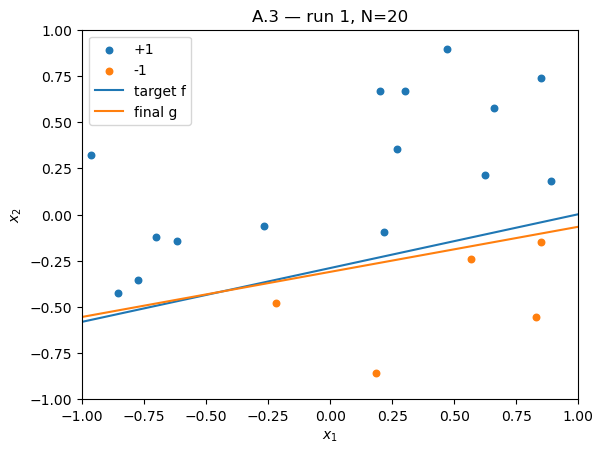

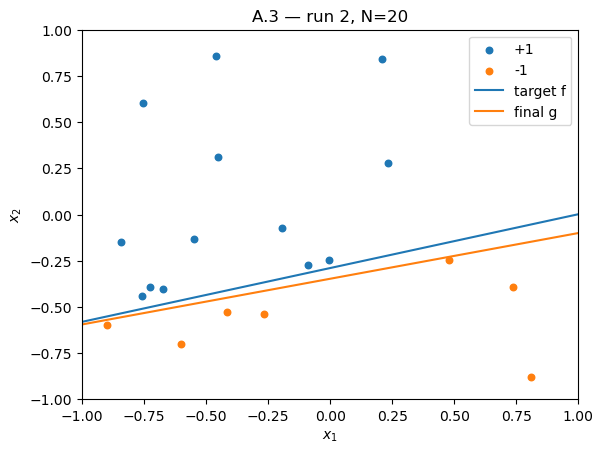

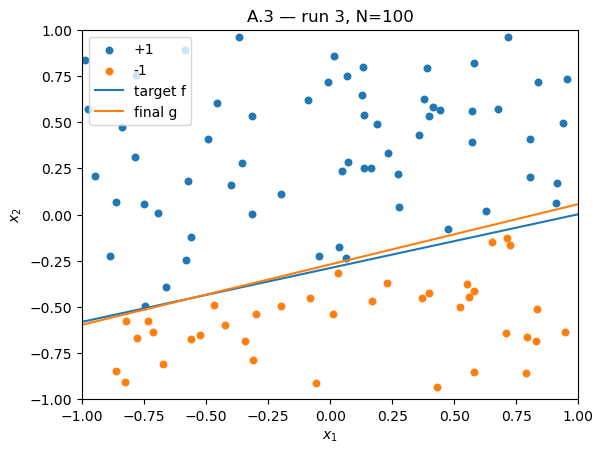

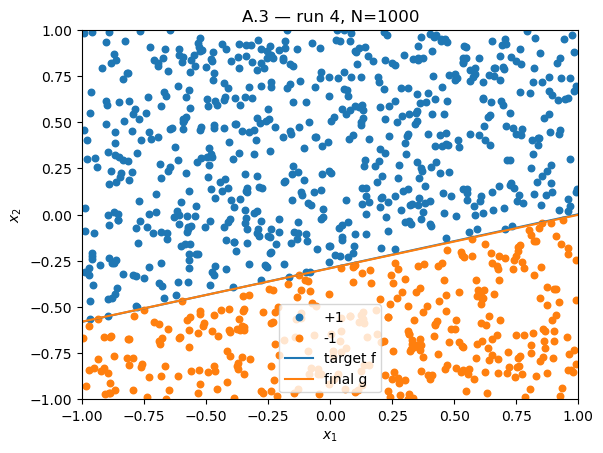

In [4]:
# A.3.1: first N=20 data set + target
X, y, _ = datasets_A3[0]
plt.figure()
plot_binary_data(X, y, "A.3.1 — N=20")
plot_line(w_target, (-1, 1), "target f")
plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.legend()
plt.show()

# A.3.2–A.3.5: target vs final PLA hypothesis
for k, (X, y, w) in enumerate(datasets_A3):
    N = len(y)
    plt.figure()
    plot_binary_data(X, y, f"A.3 — run {k+1}, N={N}")
    plot_line(w_target, (-1, 1), "target f")
    plot_line(w, (-1, 1), "final g")
    plt.xlim(-1, 1)
    plt.ylim(-1, 1)
    plt.legend()
    plt.show()



**A.3 discussion.** PLA converges on every generated data set because the labels come from a linear target.  
The learned line does not have to equal the target line: PLA only needs a separator that classifies the finite training set correctly. As \(N\) becomes larger, the data constrain the admissible separating lines more strongly, so the final separator tends to be visually closer to the target, although the number of updates is not guaranteed to grow monotonically.


## D.1 - Separable data

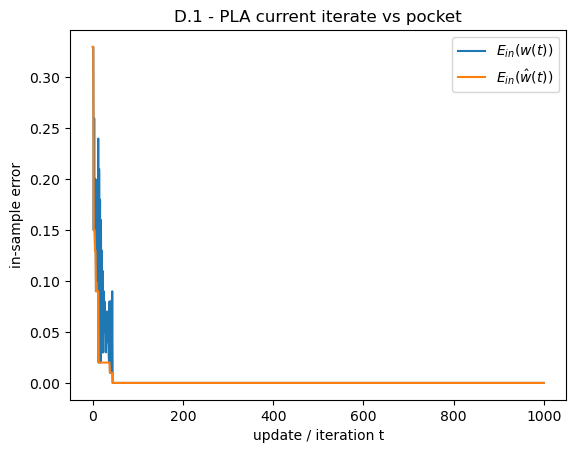

First zero training error: 44


In [5]:
rng = np.random.default_rng(SEED)
w_target_D1 = random_target(rng)
X_D1, y_D1 = generate_linear_data(100, rng, w_target_D1)

res_D1 = pocket(X_D1, y_D1, 1000, rng)

plt.figure()
plt.plot(res_D1["ein_current"], label=r"$E_{in}(w(t))$")
plt.plot(res_D1["ein_pocket"], label=r"$E_{in}(\hat w(t))$")
plt.xlabel("update / iteration t")
plt.ylabel("in-sample error")
plt.title("D.1 - PLA current iterate vs pocket")
plt.legend()
plt.show()

zero_idx = np.flatnonzero(res_D1["ein_current"] == 0)
print("First zero training error:", zero_idx[0] if len(zero_idx) else "not reached")


**D.1.2.** $E_{in}(w(t))$ is not monotone because an update that fixes the selected misclassified point may cause other points to become misclassified. The pocket curve is monotone because the code replaces `w_pocket` **only if** the current error is smaller than `best`.

**D.1.3.** On separable data, ordinary PLA is sufficient because it eventually reaches $E_{in}=0$. Pocket gives the same final training quality but costs more per update because it must evaluate (or otherwise track) the training error to decide whether the new iterate is the best so far.

## D.2 - 10% label noise

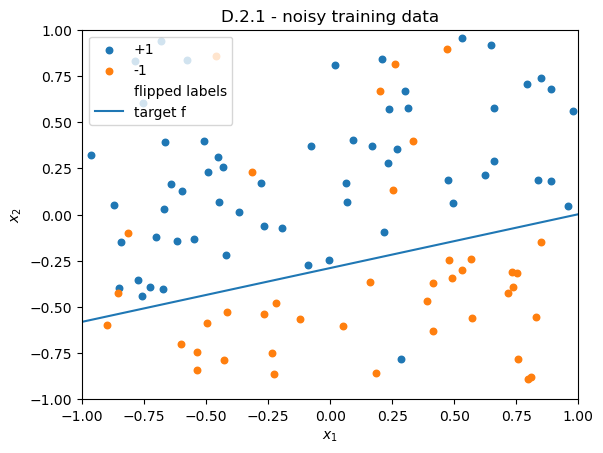

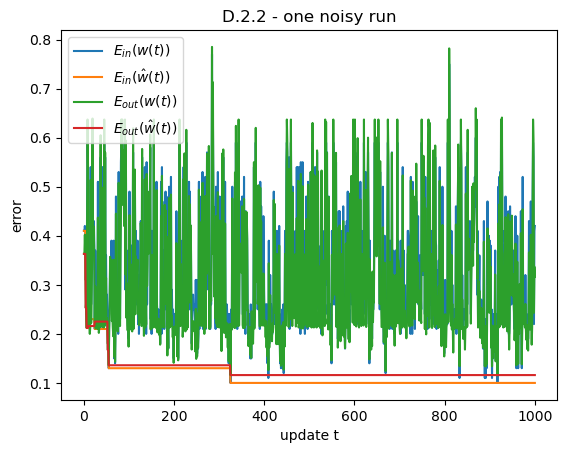

In [6]:
rng = np.random.default_rng(SEED)
w_target_D2 = random_target(rng)

X_train, y_clean_train = generate_linear_data(100, rng, w_target_D2)
y_train, flipped_train = flip_labels(y_clean_train, 0.10, rng)

X_test, y_clean_test = generate_linear_data(1000, rng, w_target_D2)
y_test, flipped_test = flip_labels(y_clean_test, 0.10, rng)

plt.figure()
plot_binary_data(X_train, y_train, "D.2.1 - noisy training data")
plt.scatter(
    X_train[flipped_train, 1], X_train[flipped_train, 2],
    s=90, facecolors="none", linewidths=1.5, label="flipped labels"
)
plot_line(w_target_D2, (-1, 1), "target f")
plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.legend()
plt.show()

res_one = pocket(X_train, y_train, 1000, rng, X_test, y_test)

plt.figure()
plt.plot(res_one["ein_current"], label=r"$E_{in}(w(t))$")
plt.plot(res_one["ein_pocket"], label=r"$E_{in}(\hat w(t))$")
plt.plot(res_one["eout_current"], label=r"$E_{out}(w(t))$")
plt.plot(res_one["eout_pocket"], label=r"$E_{out}(\hat w(t))$")
plt.xlabel("update t")
plt.ylabel("error")
plt.title("D.2.2 - one noisy run")
plt.legend()
plt.show()


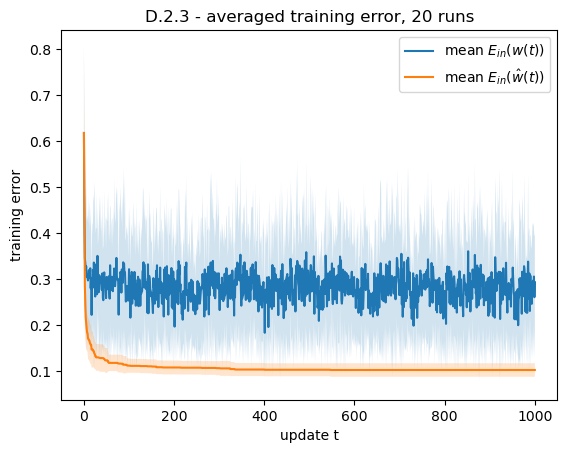

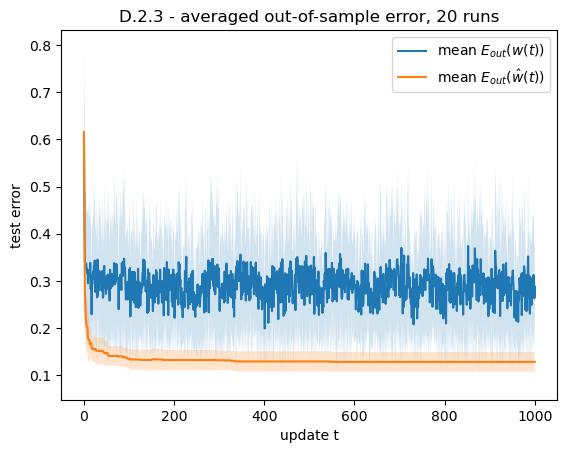

Final pocket Ein: mean = 0.10200000000000001 std = 0.014696938456699067
Final pocket Eout: mean = 0.12815000000000004 std = 0.020840525425238204


In [7]:
# D.2.3: 20 fresh repetitions
runs = []
for run in range(20):
    rng = np.random.default_rng(SEED + run)
    wt = random_target(rng)

    Xtr, ytr_clean = generate_linear_data(100, rng, wt)
    ytr, _ = flip_labels(ytr_clean, 0.10, rng)

    Xte, yte_clean = generate_linear_data(1000, rng, wt)
    yte, _ = flip_labels(yte_clean, 0.10, rng)

    runs.append(pocket(Xtr, ytr, 1000, rng, Xte, yte))

ein_cur = np.stack([r["ein_current"] for r in runs])
ein_poc = np.stack([r["ein_pocket"] for r in runs])
eout_cur = np.stack([r["eout_current"] for r in runs])
eout_poc = np.stack([r["eout_pocket"] for r in runs])

def mean_band(A):
    return A.mean(axis=0), A.std(axis=0)

m1, s1 = mean_band(ein_cur)
m2, s2 = mean_band(ein_poc)

t = np.arange(ein_cur.shape[1])
plt.figure()
plt.plot(t, m1, label=r"mean $E_{in}(w(t))$")
plt.fill_between(t, m1-s1, m1+s1, alpha=0.2)
plt.plot(t, m2, label=r"mean $E_{in}(\hat w(t))$")
plt.fill_between(t, m2-s2, m2+s2, alpha=0.2)
plt.xlabel("update t")
plt.ylabel("training error")
plt.title("D.2.3 - averaged training error, 20 runs")
plt.legend()
plt.show()

m3, s3 = mean_band(eout_cur)
m4, s4 = mean_band(eout_poc)

plt.figure()
plt.plot(t, m3, label=r"mean $E_{out}(w(t))$")
plt.fill_between(t, m3-s3, m3+s3, alpha=0.2)
plt.plot(t, m4, label=r"mean $E_{out}(\hat w(t))$")
plt.fill_between(t, m4-s4, m4+s4, alpha=0.2)
plt.xlabel("update t")
plt.ylabel("test error")
plt.title("D.2.3 - averaged out-of-sample error, 20 runs")
plt.legend()
plt.show()

final_ein = ein_poc[:, -1]
final_eout = eout_poc[:, -1]
print("Final pocket Ein: mean =", final_ein.mean(), "std =", final_ein.std())
print("Final pocket Eout: mean =", final_eout.mean(), "std =", final_eout.std())


**D.2 findings.** The pocket training error is non-increasing and normally plateaus well before 1000 updates because later PLA iterates fail to beat the best-so-far classifier.

$E_{out}(\hat{w})$ broadly follows the improvement in $E_{in}(\hat{w})$, but not monotonically and not exactly: the pocket is selected using the training set, not the test set.

The final $E_{in}$ should be near the 10% noise level, but not necessarily exactly 10%. A good learner **should not be expected to drive $E_{in}$ to zero** because the deliberately flipped labels make the sample non-separable; chasing zero training error would mean fitting noise rather than the underlying linear target.

## D.3 - Double semi-circles

In [8]:

def semicircles(N, sep, rng, rad=10.0, thk=5.0):
    n_top = N // 2
    n_bottom = N - n_top

    def sample_half_annulus(n):
        theta = rng.uniform(0, np.pi, size=n)
        # sqrt transform -> uniform in area
        r = np.sqrt(rng.uniform(rad**2, (rad + thk)**2, size=n))
        return r, theta

    rt, tt = sample_half_annulus(n_top)
    rb, tb = sample_half_annulus(n_bottom)

    top = np.column_stack([rt*np.cos(tt), rt*np.sin(tt)])
    bottom = np.column_stack([
        rb*np.cos(tb) + rad + thk/2,
        -rb*np.sin(tb) - sep
    ])

    X2 = np.vstack([top, bottom])
    y = np.concatenate([-np.ones(n_top, dtype=int), np.ones(n_bottom, dtype=int)])

    p = rng.permutation(N)
    X2, y = X2[p], y[p]
    return np.column_stack([np.ones(N), X2]), y


sep=5 updates: 12 converged: True


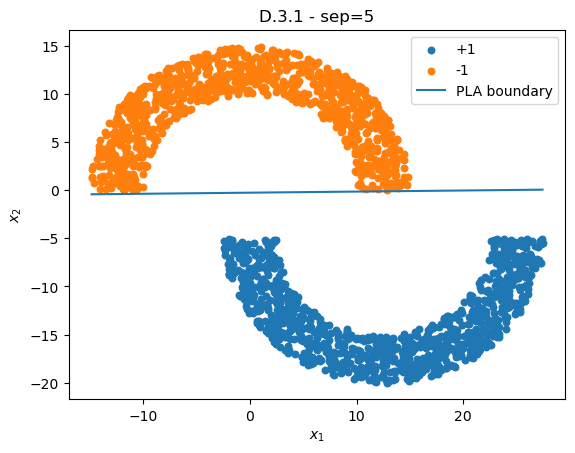

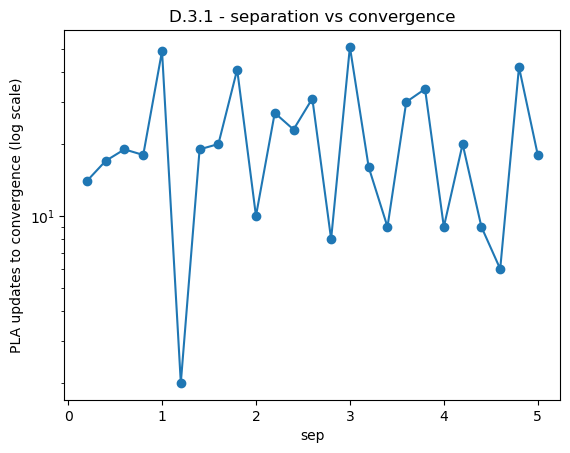

In [9]:

# D.3.1 — sep=5
rng = np.random.default_rng(SEED)
X_sep5, y_sep5 = semicircles(2000, 5, rng)
w_sep5, updates_sep5, conv_sep5, _ = pla(X_sep5, y_sep5, rng, max_updates=2_000_000)

print("sep=5 updates:", updates_sep5, "converged:", conv_sep5)

plt.figure()
plot_binary_data(X_sep5, y_sep5, "D.3.1 - sep=5")
plot_line(w_sep5, (X_sep5[:,1].min(), X_sep5[:,1].max()), "PLA boundary")
plt.legend()
plt.show()

# sweep sep = 0.2,...,5
seps = np.arange(0.2, 5.01, 0.2)
updates = []

for k, sep in enumerate(seps):
    rng = np.random.default_rng(SEED + k)
    Xs, ys = semicircles(2000, float(sep), rng)
    _, u, converged, _ = pla(Xs, ys, rng, max_updates=2_000_000)
    updates.append(u if converged else np.nan)

plt.figure()
plt.plot(seps, updates, marker="o")
plt.yscale("log")
plt.xlabel("sep")
plt.ylabel("PLA updates to convergence (log scale)")
plt.title("D.3.1 - separation vs convergence")
plt.show()


**D.3.1 interpretation.** As the geometric separation becomes smaller, the achievable margin generally becomes smaller and PLA can take more updates, although an individual random run is noisy and need not be monotone in `sep`.

This agrees with the perceptron convergence bound: the bound worsens as the normalized margin $\rho/R$ shrinks.

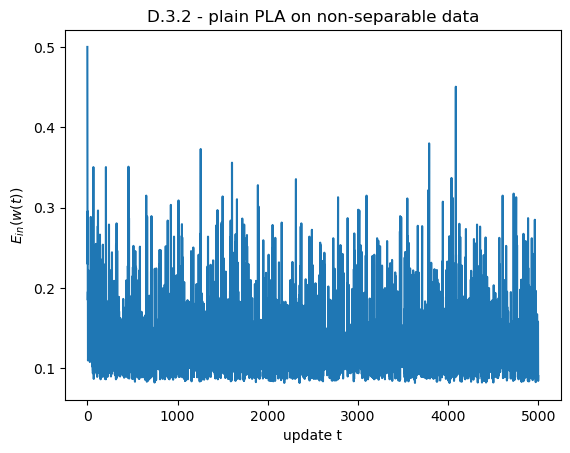

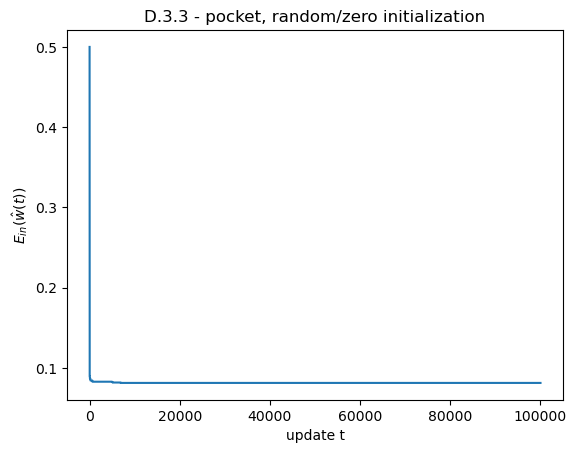

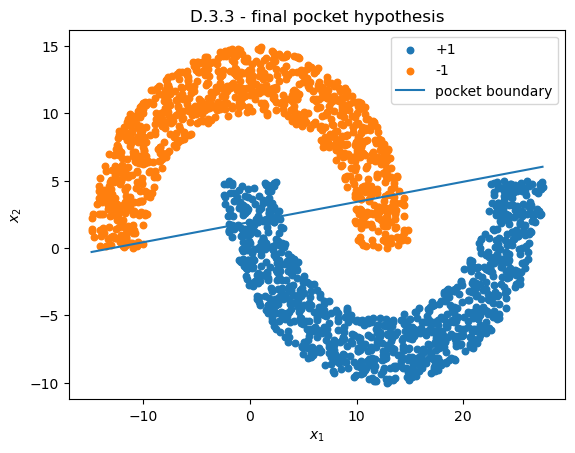

Final pocket Ein: 0.0815
Pocket runtime (s): 7.885079899999255


In [10]:
# D.3.2–D.3.5: overlapping data, sep=-5
rng = np.random.default_rng(SEED)
X_ov, y_ov = semicircles(2000, -5, rng)

# Plain PLA behavior over first 5000 updates:
_, _, _, pla_hist = pla(X_ov, y_ov, rng, max_updates=5000, record=True)

plt.figure()
plt.plot(pla_hist)
plt.xlabel("update t")
plt.ylabel(r"$E_{in}(w(t))$")
plt.title("D.3.2 - plain PLA on non-separable data")
plt.show()

# Pocket for 100,000 updates
rng = np.random.default_rng(SEED)
start = time.perf_counter()
res_rand = pocket(X_ov, y_ov, 100_000, rng)
time_pocket_random = time.perf_counter() - start

plt.figure()
plt.plot(res_rand["ein_pocket"])
plt.xlabel("update t")
plt.ylabel(r"$E_{in}(\hat w(t))$")
plt.title("D.3.3 - pocket, random/zero initialization")
plt.show()

plt.figure()
plot_binary_data(X_ov, y_ov, "D.3.3 - final pocket hypothesis")
plot_line(res_rand["w_pocket"], (X_ov[:,1].min(), X_ov[:,1].max()), "pocket boundary")
plt.legend()
plt.show()

print("Final pocket Ein:", res_rand["ein_pocket"][-1])
print("Pocket runtime (s):", time_pocket_random)


Linear regression Ein: 0.0955
Linear regression runtime (s): 0.0006431000001612119


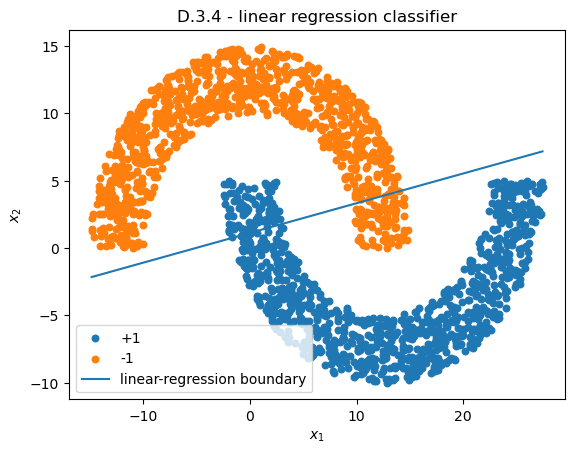

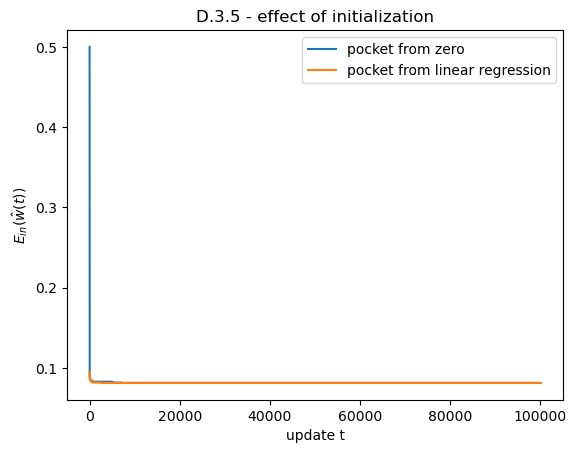

Final pocket Ein from zero: 0.0815
Final pocket Ein from regression: 0.0815


In [11]:
# D.3.4 — linear regression
start = time.perf_counter()
w_lin = np.linalg.pinv(X_ov) @ y_ov
time_lin = time.perf_counter() - start
ein_lin = classification_error(w_lin, X_ov, y_ov)

print("Linear regression Ein:", ein_lin)
print("Linear regression runtime (s):", time_lin)

plt.figure()
plot_binary_data(X_ov, y_ov, "D.3.4 - linear regression classifier")
plot_line(w_lin, (X_ov[:,1].min(), X_ov[:,1].max()), "linear-regression boundary")
plt.legend()
plt.show()

# D.3.5 — initialize pocket from linear regression
rng = np.random.default_rng(SEED + 1)
res_lin_init = pocket(X_ov, y_ov, 100_000, rng, w0=w_lin)

plt.figure()
plt.plot(res_rand["ein_pocket"], label="pocket from zero")
plt.plot(res_lin_init["ein_pocket"], label="pocket from linear regression")
plt.xlabel("update t")
plt.ylabel(r"$E_{in}(\hat w(t))$")
plt.title("D.3.5 - effect of initialization")
plt.legend()
plt.show()

print("Final pocket Ein from zero:", res_rand["ein_pocket"][-1])
print("Final pocket Ein from regression:", res_lin_init["ein_pocket"][-1])


**D.3.2.** Plain PLA does not converge for `sep=-5` because the data are non-separable. The current $E_{in}(w(t))$ keeps fluctuating: every update fixes one currently misclassified point but can spoil others.

**D.3.4.** Linear regression is dramatically cheaper because it gives an analytic initialization through the pseudoinverse. Its classification error can be slightly worse than a long pocket run, but it is available immediately.

**D.3.5.** Regression initialization starts pocket with a much better classifier than $w=0$. Even if both runs eventually reach a similar best $E_{in}$, the regression-started run begins near a useful region of weight space. This supports combining a cheap analytic solution with an iterative improvement method.

# D.5 — Real data: MNIST digits 1 vs 5

We keep only digits **1** and **5** and assign

$$
y = +1 \quad \text{for digit 1}, 
\qquad
y = -1 \quad \text{for digit 5}.
$$

Each image is scaled to $[0,1]$ and reduced to two handcrafted features:

$$
x_1 = \text{intensity}
= \frac{1}{784}\sum_{i,j} I_{ij},
$$

$$
x_2 = \text{symmetry}
= -\frac{1}{784}
\sum_{i,j}
\left|I_{ij} - I^{\text{flip}}_{ij}\right|.
$$

Both features are standardized using **training-set statistics only**.

We must not use the test set to compute the mean or standard deviation because that would leak information from the test set into the learning pipeline. The test set must remain unseen until final evaluation.

In [12]:
from sklearn.datasets import fetch_openml

print("Downloading/loading MNIST. The first run can take a few minutes...")
X_all, y_all = fetch_openml(
    "mnist_784",
    version=1,
    return_X_y=True,
    as_frame=False
)

X_all = X_all.astype(np.float32)
y_all = y_all.astype(np.int64)

# Standard MNIST split specified in the homework.
X_train_raw, y_train_raw = X_all[:60000], y_all[:60000]
X_test_raw, y_test_raw = X_all[60000:], y_all[60000:]

train_mask = np.isin(y_train_raw, [1, 5])
test_mask = np.isin(y_test_raw, [1, 5])

X15_train_raw = X_train_raw[train_mask]
digits_train = y_train_raw[train_mask]
X15_test_raw = X_test_raw[test_mask]
digits_test = y_test_raw[test_mask]

y15_train = np.where(digits_train == 1, 1, -1).astype(int)
y15_test = np.where(digits_test == 1, 1, -1).astype(int)

print("1-vs-5 training examples:", len(y15_train))
print("  digit 1:", np.sum(digits_train == 1))
print("  digit 5:", np.sum(digits_train == 5))
print("1-vs-5 test examples:", len(y15_test))
print("  digit 1:", np.sum(digits_test == 1))
print("  digit 5:", np.sum(digits_test == 5))

Downloading/loading MNIST. The first run can take a few minutes...
1-vs-5 training examples: 12163
  digit 1: 6742
  digit 5: 5421
1-vs-5 test examples: 2027
  digit 1: 1135
  digit 5: 892


In [13]:
def mnist_two_features(X_flat):
    # X_flat has shape (N, 784), with original pixels in [0,255].
    imgs = X_flat.reshape(-1, 28, 28).astype(np.float32) / 255.0

    intensity = imgs.mean(axis=(1, 2))

    flipped = imgs[:, :, ::-1]
    symmetry = -np.abs(imgs - flipped).mean(axis=(1, 2))

    return np.column_stack([intensity, symmetry]), imgs

F_train_raw, imgs_train_15 = mnist_two_features(X15_train_raw)
F_test_raw, imgs_test_15 = mnist_two_features(X15_test_raw)

# Standardize with TRAINING statistics only.
feature_mean = F_train_raw.mean(axis=0)
feature_std = F_train_raw.std(axis=0, ddof=0)

F_train = (F_train_raw - feature_mean) / feature_std
F_test = (F_test_raw - feature_mean) / feature_std

# Add bias coordinate.
X15_train = np.column_stack([np.ones(len(F_train)), F_train])
X15_test = np.column_stack([np.ones(len(F_test)), F_test])

print("Training feature mean before standardization:", feature_mean)
print("Training feature std before standardization:", feature_std)
print("Standardized training means:", F_train.mean(axis=0))
print("Standardized training stds:", F_train.std(axis=0))

Training feature mean before standardization: [ 0.09950915 -0.12127413]
Training feature std before standardization: [0.03967854 0.04366779]
Standardized training means: [7.3345395e-06 8.8804791e-06]
Standardized training stds: [1.0000011 1.0000007]


## D.5.1 - Training data in the two-feature plane

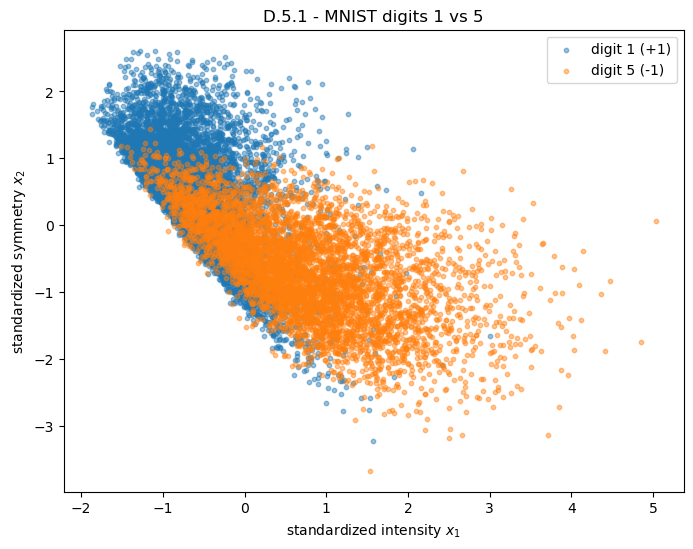

In [14]:
plt.figure(figsize=(8, 6))
plt.scatter(
    F_train[digits_train == 1, 0],
    F_train[digits_train == 1, 1],
    s=10, alpha=0.45, label="digit 1 (+1)"
)
plt.scatter(
    F_train[digits_train == 5, 0],
    F_train[digits_train == 5, 1],
    s=10, alpha=0.45, label="digit 5 (-1)"
)
plt.xlabel("standardized intensity $x_1$")
plt.ylabel("standardized symmetry $x_2$")
plt.title("D.5.1 - MNIST digits 1 vs 5")
plt.legend()
plt.show()

**D.5.1 discussion.** The two classes overlap in the intensity–symmetry plane, so they are **not linearly separable** using only these two features. Therefore plain PLA should not be expected to terminate: on non-separable data there is always at least one misclassified training point, so PLA can continue updating indefinitely.

## D.5.2 - Pocket on a random \(N=1000\) training subsample

Linear-regression initialization: [ 0.09809527 -0.55743312  0.16584266]
Initial subsample Ein: 0.177


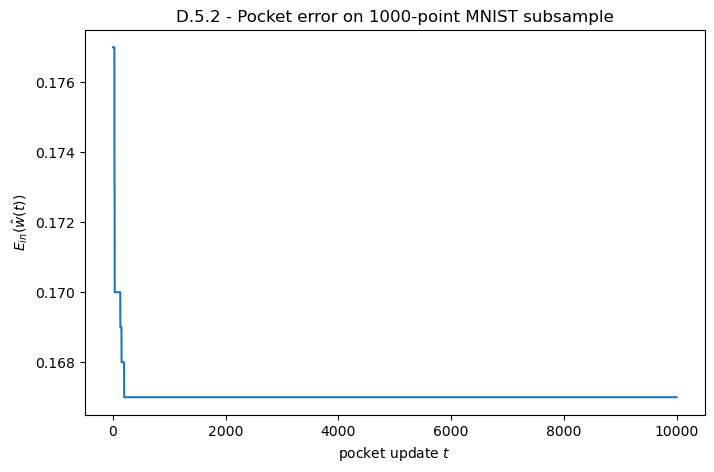

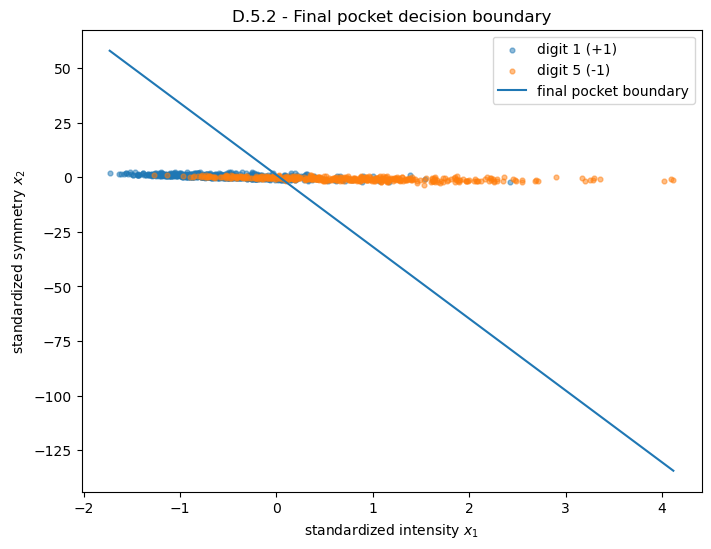

In [15]:
rng = np.random.default_rng(SEED)

sub_idx = rng.choice(len(X15_train), size=1000, replace=False)
X_sub = X15_train[sub_idx]
y_sub = y15_train[sub_idx]

# Linear-regression initialization.
w_lin_mnist = np.linalg.pinv(X_sub) @ y_sub

print("Linear-regression initialization:", w_lin_mnist)
print("Initial subsample Ein:", classification_error(w_lin_mnist, X_sub, y_sub))

res_mnist = pocket(
    X_sub,
    y_sub,
    T=10_000,
    rng=rng,
    w0=w_lin_mnist
)

w_mnist = res_mnist["w_pocket"]

plt.figure(figsize=(8, 5))
plt.plot(res_mnist["ein_pocket"])
plt.xlabel("pocket update $t$")
plt.ylabel(r"$E_{in}(\hat w(t))$")
plt.title("D.5.2 - Pocket error on 1000-point MNIST subsample")
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(
    X_sub[y_sub == 1, 1],
    X_sub[y_sub == 1, 2],
    s=12, alpha=0.5, label="digit 1 (+1)"
)
plt.scatter(
    X_sub[y_sub == -1, 1],
    X_sub[y_sub == -1, 2],
    s=12, alpha=0.5, label="digit 5 (-1)"
)
plot_line(
    w_mnist,
    (X_sub[:, 1].min(), X_sub[:, 1].max()),
    "final pocket boundary"
)
plt.xlabel("standardized intensity $x_1$")
plt.ylabel("standardized symmetry $x_2$")
plt.title("D.5.2 - Final pocket decision boundary")
plt.legend()
plt.show()

The pocket curve is non-increasing because the pocket vector is replaced only when a new iterate has a lower training error. Starting from linear regression gives the iterative algorithm an already useful linear separator rather than beginning from the zero vector.

## D.5.3 — Subsample, full-training, and test errors

In [16]:
ein_subsample = classification_error(w_mnist, X_sub, y_sub)
ein_full_train = classification_error(w_mnist, X15_train, y15_train)
eout_test = classification_error(w_mnist, X15_test, y15_test)

print(f"Final subsample Ein:       {ein_subsample:.4f} ({100*ein_subsample:.2f}%)")
print(f"Full training-set error:   {ein_full_train:.4f} ({100*ein_full_train:.2f}%)")
print(f"Test Eout estimate:        {eout_test:.4f} ({100*eout_test:.2f}%)")
print(f"Test - subsample gap:      {eout_test - ein_subsample:+.4f}")

Final subsample Ein:       0.1670 (16.70%)
Full training-set error:   0.1787 (17.87%)
Test Eout estimate:        0.1648 (16.48%)
Test - subsample gap:      -0.0022


**D.5.3 discussion.** The error on the 1000-point subsample is expected to be the most optimistic number because the pocket vector is explicitly selected to minimize error on that subsample. The error on the full training set and the independent test set are more realistic measures of how the selected classifier behaves away from those 1000 examples.

This relates directly to D.4: selecting the minimum training error over many pocket iterates introduces an optimistic selection bias. The independent test set is therefore the appropriate source for estimating performance on new examples.

## D.5.4 - Inspect misclassified test images

Number of misclassified test images: 334


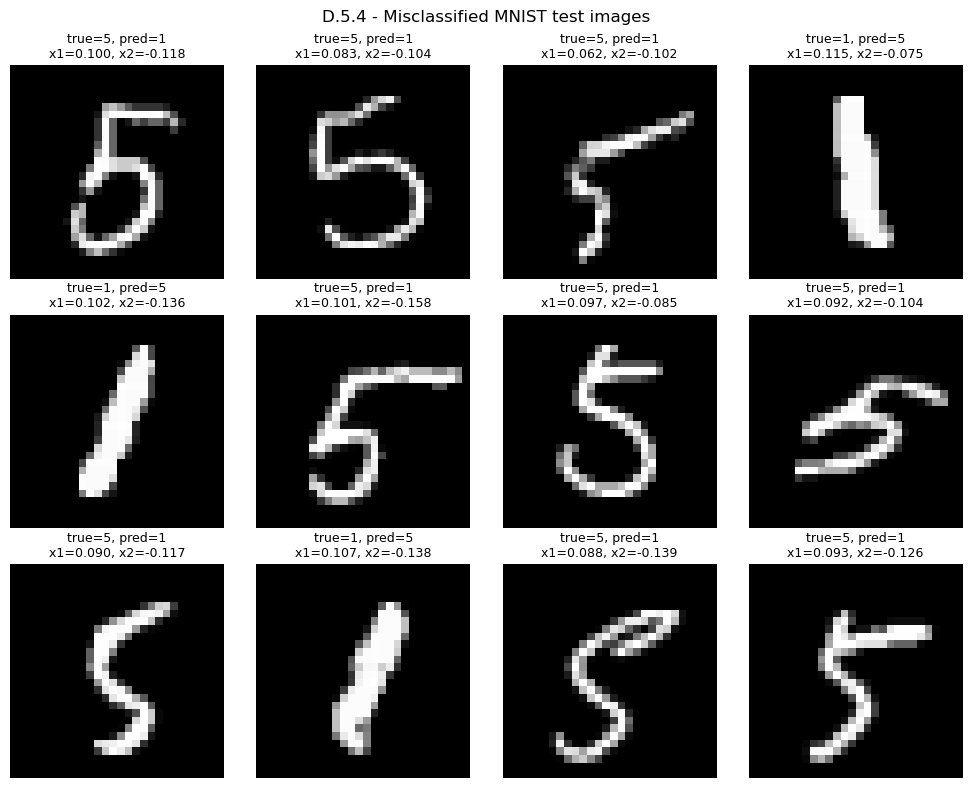

In [17]:
test_pred = sgn(X15_test @ w_mnist).astype(int)
mis_idx = np.flatnonzero(test_pred != y15_test)

print("Number of misclassified test images:", len(mis_idx))

n_show = min(12, len(mis_idx))
show_idx = mis_idx[:n_show]

fig, axes = plt.subplots(3, 4, figsize=(10, 8))
axes = axes.ravel()

for ax in axes:
    ax.axis("off")

for ax, idx in zip(axes, show_idx):
    true_digit = int(digits_test[idx])
    pred_digit = 1 if test_pred[idx] == 1 else 5
    intensity, symmetry = F_test_raw[idx]

    ax.imshow(imgs_test_15[idx], cmap="gray")
    ax.set_title(
        f"true={true_digit}, pred={pred_digit}\n"
        f"x1={intensity:.3f}, x2={symmetry:.3f}",
        fontsize=9
    )
    ax.axis("off")

plt.suptitle("D.5.4 - Misclassified MNIST test images")
plt.tight_layout()
plt.show()

**D.5.4 discussion.** Many of the errors are not simply caused by choosing a slightly different straight decision boundary. Intensity compresses all 784 pixels into one average brightness value, and symmetry compresses the image into one left–right similarity value. Very different digit shapes can therefore map to nearly the same \((x_1,x_2)\).

The main limitation is consequently the **feature representation itself**.

One useful additional feature would be a measure of **vertical-stroke concentration**, for example the fraction of ink near the center columns. Digit 1 often contains one dominant central vertical stroke, whereas digit 5 usually distributes substantial ink across top, middle, and lower horizontal/curved regions. Such a feature could separate examples that have similar intensity and symmetry but different shapes.

## D.5.5 - Pocket on all 784 pixels

Two-feature results
  subsample Ein: 0.167
  full train: 0.17873879799391598
  test: 0.16477553034040454

784-pixel results
  subsample Ein: 0.0
  full train: 0.05903148894187289
  test: 0.051307350764676865


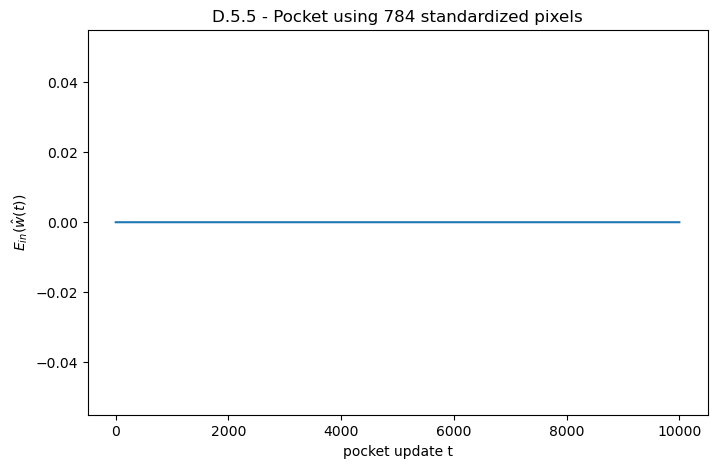

In [18]:
RUN_D5_EXTRA_CREDIT = True

if RUN_D5_EXTRA_CREDIT:
    P_train = X15_train_raw.astype(np.float32) / 255.0
    P_test = X15_test_raw.astype(np.float32) / 255.0

    pix_mean = P_train.mean(axis=0)
    pix_std = P_train.std(axis=0)
    pix_std[pix_std < 1e-12] = 1.0

    P_train_z = (P_train - pix_mean) / pix_std
    P_test_z = (P_test - pix_mean) / pix_std

    P_train_aug = np.column_stack([np.ones(len(P_train_z)), P_train_z])
    P_test_aug = np.column_stack([np.ones(len(P_test_z)), P_test_z])

    P_sub = P_train_aug[sub_idx]

    w_raw_lin = np.linalg.pinv(P_sub) @ y_sub

    rng_raw = np.random.default_rng(SEED)
    res_raw = pocket(
        P_sub,
        y_sub,
        T=10_000,
        rng=rng_raw,
        w0=w_raw_lin
    )
    w_raw = res_raw["w_pocket"]

    raw_sub_ein = classification_error(w_raw, P_sub, y_sub)
    raw_train_error = classification_error(w_raw, P_train_aug, y15_train)
    raw_test_error = classification_error(w_raw, P_test_aug, y15_test)

    print("Two-feature results")
    print("  subsample Ein:", ein_subsample)
    print("  full train:", ein_full_train)
    print("  test:", eout_test)

    print("\n784-pixel results")
    print("  subsample Ein:", raw_sub_ein)
    print("  full train:", raw_train_error)
    print("  test:", raw_test_error)

    plt.figure(figsize=(8, 5))
    plt.plot(res_raw["ein_pocket"])
    plt.xlabel("pocket update t")
    plt.ylabel(r"$E_{in}(\hat w(t))$")
    plt.title("D.5.5 - Pocket using 784 standardized pixels")
    plt.show()
else:
    print("Set RUN_D5_EXTRA_CREDIT = True if you want to run it.")

**D.5.5 interpretation.** A 784-pixel linear classifier has far more degrees of freedom than the two-feature classifier, so it can usually fit the training sample more closely. Whether the test error improves by the same amount is the important question. The comparison illustrates the Section C approximation–generalization trade-off: increasing model/representation complexity can reduce approximation error, but the resulting classifier also has more freedom to fit sample-specific variation.